# Preregistration Statement 2: Mercedes and temperature

**Hypothesis:** Mercedes performs better than usual (lower `relative_pace`) when temperatures are cooler.

**Analysis (as preregistered):** We will need to run the linear regression `relative_pace` on air temperature (`temperature_2m`), team dummies (Ferrari = reference), and the interaction temperature × Mercedes. This will test whether the interaction is > 0. Repeat with cloud cover instead of temperature in daytime sessions only.

**Model:** `relative_pace = b0 + b1·Temp + team dummies + b2·(Temp × Mercedes) + error`
- **b2** = extra change in relative pace per +1 degree Celsius for Mercedes compared with all other teams.
- **H0 (null hypothesis):** b2 = 0. **H1 (alternate hypothesis):** b2 > 0 (Mercedes gets relatively slower as it gets hotter).

**Tests used:** (1) t-test / p-value on b2 from the regression table; (2) permutation test. Robust SEs as a check. alpha-value = 0.05 [meaning our p-values must be below this to be considered significant]

In [12]:
%pip install -q statsmodels plotly seaborn pandas matplotlib

In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
import statsmodels.formula.api as smf
sns.set_theme(style="whitegrid")

df = pd.read_csv("analysis_ready.csv") # cleaned file from the cleaning notebook
df["is_mercedes"] = df["is_mercedes"].astype(int) # True/False -> 1/0 for the formula
print(df.shape, "| sessions:", df["session_key"].nunique())
df[["relative_pace", "temperature_2m", "cloud_cover"]].describe().round(2)

(878, 34) | sessions: 88


,relative_pace,temperature_2m,cloud_cover
count,868.00,878.00,878.00
mean,0.00,23.53,54.99
std,1.35,5.35,40.30
min,-2.53,10.10,0.00
25%,-0.44,20.02,10.50
50%,-0.11,23.67,53.00
75%,0.19,27.35,100.00
max,13.29,36.35,100.00


## Background: temperature across circuits
*Why this figure:* temperature has to vary across sessions for the test to work. The map shows the circuits colored by average air temperature at session start (hover for details). Coordinates are taken from each race location. Inspiration for this figure came from Discussion 9 choropleths and scatter_geos.

In [14]:
# circuit coordinates
circuit_coords = {
    "Sakhir": (26.0325, 50.5106), "Jeddah": (21.6319, 39.1044), "Melbourne": (-37.8497, 144.9680),
    "Baku": (40.3725, 49.8533), "Miami": (25.9581, -80.2389), "Monte Carlo": (43.7347, 7.4206),
    "Catalunya": (41.5700, 2.2611), "Montreal": (45.5017, -73.5228), "Spielberg": (47.2197, 14.7647),
    "Silverstone": (52.0786, -1.0169), "Hungaroring": (47.5789, 19.2486), "Spa-Francorchamps": (50.4372, 5.9714),
    "Zandvoort": (52.3888, 4.5409), "Monza": (45.6156, 9.2811), "Singapore": (1.2914, 103.8640),
    "Suzuka": (34.8431, 136.5410), "Lusail": (25.4900, 51.4542), "Austin": (30.1328, -97.6411),
    "Mexico City": (19.4042, -99.0907), "Interlagos": (-23.7036, -46.6997), "Las Vegas": (36.1147, -115.1728),
    "Yas Marina Circuit": (24.4672, 54.6031), "Shanghai": (31.3389, 121.2197), "Imola": (44.3439, 11.7167),
}
coords_df = pd.DataFrame.from_dict(circuit_coords, orient="index", columns=["latitude", "longitude"]).rename_axis("circuit_short_name").reset_index()

circuits = (df.groupby("circuit_short_name")["temperature_2m"].mean().reset_index(name="mean_temp_c")
              .merge(coords_df, on="circuit_short_name", how="left"))
fig = px.scatter_geo(circuits, lat="latitude", lon="longitude", color="mean_temp_c", hover_name="circuit_short_name",
                     color_continuous_scale="RdYlBu_r", projection="natural earth",
                     labels={"mean_temp_c": "Mean air temp (°C)"})
fig.update_traces(marker=dict(size=11, line=dict(width=0.5, color="black")))
fig.update_layout(margin=dict(l=0, r=0, t=10, b=0), height=400)
fig.show()

## 1. Temperature model
**Figure:** relative pace vs temperature for Mercedes and all other teams. b2, our experimental variable, is the difference between the two fitted slopes; the hypothesis predicts Mercedes results will slope upward more steeply.

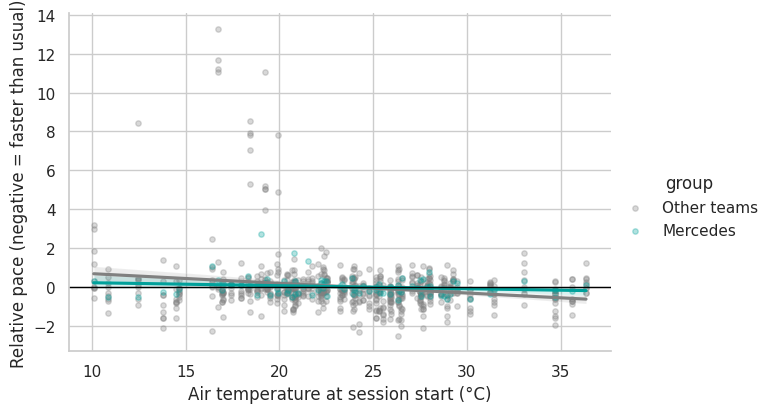

In [15]:
g = sns.lmplot(data=df.assign(group=np.where(df["is_mercedes"] == 1, "Mercedes", "Other teams")),
               x="temperature_2m", y="relative_pace", hue="group", scatter_kws={"alpha": 0.3, "s": 15},
               palette={"Mercedes": "#00A19B", "Other teams": "gray"}, height=4.3, aspect=1.5)
g.ax.axhline(0, color="black", lw=1)
g.set_axis_labels("Air temperature at session start (°C)", "Relative pace (negative = faster than usual)")
plt.show()

In [16]:
formula_t = 'relative_pace ~ temperature_2m + C(team_name, Treatment("Ferrari")) + temperature_2m:is_mercedes'
term_t = "temperature_2m:is_mercedes"
fit_t = smf.ols(formula_t, data=df).fit()
print(fit_t.summary())

                            OLS Regression Results                            
Dep. Variable:          relative_pace   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     2.865
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00106
Time:                        04:29:53   Log-Likelihood:                -1476.0
No. Observations:                 868   AIC:                             2976.
Df Residuals:                     856   BIC:                             3033.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

### Test 1: t-test on b2 (one-sided, preregistered)
The table gives a two-sided p-value. Because H1, our alt hypothesis, is b2 > 0, the one-sided p is half of it if b2 is positive, and 1 − half of it if b2 is negative.

In [25]:
b2_t = fit_t.params[term_t]
p_two_t = fit_t.pvalues[term_t]
p_one_t = p_two_t / 2 if b2_t > 0 else 1 - p_two_t / 2
ci = fit_t.conf_int().loc[term_t]
print("b2 (experimental var):", round(b2_t, 4))
print("Standard error:", round(fit_t.bse[term_t], 4))
print("95% CI:", round(ci[0], 4), "to", round(ci[1], 4))
print("Two-sided p-value:", round(p_two_t, 4))
print("One-sided p-value:", round(p_one_t, 4))
print("Decision at alpha = 0.05:", "reject H0" if p_one_t < 0.05 else "fail to reject H0")

b2 (experimental var): 0.0344
Standard error: 0.0282
95% CI: -0.0209 to 0.0897
Two-sided p-value: 0.2225
One-sided p-value: 0.1112
Decision at alpha = 0.05: fail to reject H0


### Test 2: permutation test
Shuffle the temperature values across sessions (the 10 teams in a session stay together because they share the same weather), refit, and record b2. Repeat 1,000 times. The p-value is the share of shuffled b2 values at least as large as ours. This aims to test the answer from previous Test that rejected our null without reliance on the constructed regression model. It gives us another piece of information and checks our result.

Permutation p-value (one-sided): 0.038


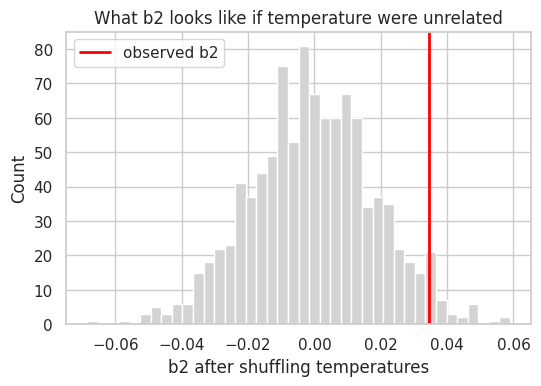

In [26]:
np.random.seed(2950)
sess = df[["session_key", "temperature_2m"]].drop_duplicates("session_key")
perm_t = []
for _ in range(1000):
    s = sess.copy()
    s["temperature_2m"] = np.random.permutation(s["temperature_2m"].values)
    d = df.drop(columns="temperature_2m").merge(s, on="session_key")
    perm_t.append(smf.ols(formula_t, data=d).fit().params[term_t])
perm_t = np.array(perm_t)
p_perm_t = (perm_t >= b2_t).mean()
print("Permutation p-value (one-sided):", round(p_perm_t, 4))

plt.figure(figsize=(6, 3.8))
plt.hist(perm_t, bins=40, color="lightgray")
plt.axvline(b2_t, color="red", lw=2, label="observed b2")
plt.xlabel("b2 after shuffling temperatures"); plt.ylabel("Count"); plt.legend()
plt.title("What b2 looks like if temperature were unrelated")
plt.show()

The permutated p-value being 0.038 implies that about 3.8% of the 1,000 shuffles produced a b2 as large as ours or larger. p = 0.038 < 0.05 (alpha value), so we reject the H0 (null hypothesis) under this permutated test/condition. This data does not speak heavily to effect size or noise, but indicates that the values are different than chance. However, this calls into question whether we should rely heavily on regression models for our data or permutated models.

### Check: robust standard errors
HC3 and clustering by session, since the 10 teams in a session share one weather value.

In [19]:
# Drop rows with missing values in the model variables to avoid alignment issues
df_clean = df.dropna(subset=["relative_pace", "temperature_2m"])

fit_t = smf.ols(formula_t, data=df_clean).fit()
fit_hc3 = smf.ols(formula_t, data=df_clean).fit(cov_type="HC3")
fit_clu = smf.ols(formula_t, data=df_clean).fit(cov_type="cluster", cov_kwds={"groups": df_clean["session_key"]})

pd.DataFrame([{"SE type": n, "b2": f.params[term_t], "std_err": f.bse[term_t], "p_two_sided": f.pvalues[term_t]}
              for n, f in [("Classical OLS", fit_t), ("HC3 robust", fit_hc3), ("Cluster by session", fit_clu)]]).round(4)

,SE type,b2,std_err,p_two_sided
0,Classical OLS,0.0344,0.0282,0.2225
1,HC3 robust,0.0344,0.0149,0.0213
2,Cluster by session,0.0344,0.0195,0.0781


### Predicting and outliers
Predicted relative pace at a cool vs hot session (10th and 90th percentile of temperature), then the residual plot.

,team_name,is_mercedes,temperature_2m,predicted_relative_pace
0,Mercedes,1,16.95,0.102
1,Mercedes,1,29.45,-0.090
2,Ferrari,0,16.95,0.330
3,Ferrari,0,29.45,-0.292


Mercedes cool -> hot: -0.192 pp | Ferrari: -0.622 pp


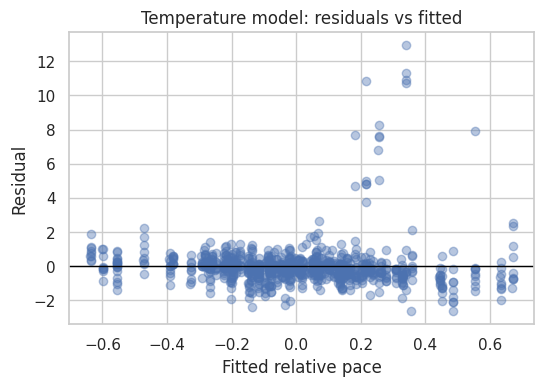

In [27]:
q10, q90 = df["temperature_2m"].quantile([0.1, 0.9])
new = pd.DataFrame({"team_name": ["Mercedes", "Mercedes", "Ferrari", "Ferrari"], "is_mercedes": [1, 1, 0, 0],
                    "temperature_2m": [q10, q90, q10, q90]})
new["predicted_relative_pace"] = fit_t.predict(new)
display(new.round(3))
print(f"Mercedes cool -> hot: {new.loc[1,'predicted_relative_pace'] - new.loc[0,'predicted_relative_pace']:+.3f} pp | "
      f"Ferrari: {new.loc[3,'predicted_relative_pace'] - new.loc[2,'predicted_relative_pace']:+.3f} pp")

plt.figure(figsize=(6, 3.8))
plt.scatter(fit_t.fittedvalues, fit_t.resid, alpha=0.4)
plt.axhline(0, color="black", lw=1)
plt.xlabel("Fitted relative pace");
plt.ylabel("Residual");
plt.title("Temperature model: residuals vs fitted")
plt.show()

## 2. Cloud-cover version (daytime sessions only)
Same model with `cloud_cover`, using `is_night == False`. The preregistration gives no direction for cloud cover (more cloud should mean a cooler track, so the matching prediction is b2 < 0), so the **two-sided p-value is primary**.

Daytime rows: 679 | daytime sessions: 68


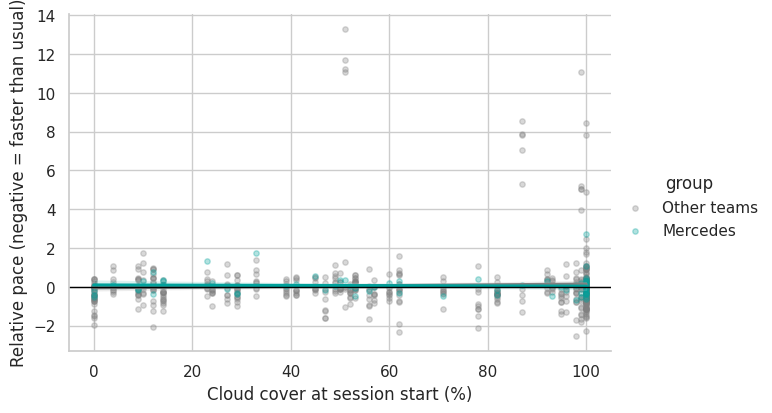

                            OLS Regression Results                            
Dep. Variable:          relative_pace   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.013
Method:                 Least Squares   F-statistic:                    0.2022
Date:                Tue, 10 Nov 2026   Prob (F-statistic):              0.997
Time:                        04:30:32   Log-Likelihood:                -1211.8
No. Observations:                 669   AIC:                             2448.
Df Residuals:                     657   BIC:                             2502.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [21]:
day = df[df["is_night"] == False]
print("Daytime rows:", len(day), "| daytime sessions:", day["session_key"].nunique())

g = sns.lmplot(data=day.assign(group=np.where(day["is_mercedes"] == 1, "Mercedes", "Other teams")),
               x="cloud_cover", y="relative_pace", hue="group", scatter_kws={"alpha": 0.3, "s": 15},
               palette={"Mercedes": "#00A19B", "Other teams": "gray"}, height=4.3, aspect=1.5)
g.ax.axhline(0, color="black", lw=1)
g.set_axis_labels("Cloud cover at session start (%)", "Relative pace (negative = faster than usual)")
plt.show()

formula_c = 'relative_pace ~ cloud_cover + C(team_name, Treatment("Ferrari")) + cloud_cover:is_mercedes'
term_c = "cloud_cover:is_mercedes"
fit_c = smf.ols(formula_c, data=day).fit()
print(fit_c.summary())

b2 = -0.00249 pp per +1% cloud (-0.0249 pp per +10%), 95% CI [-0.01296, 0.00798]
two-sided p = 0.6403 | one-sided p (b2 < 0) = 0.3201
Permutation p-value (two-sided) = 0.4830


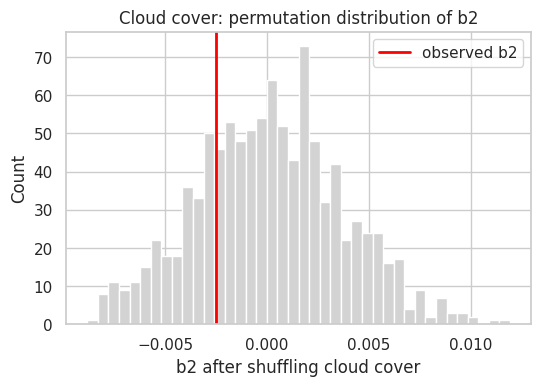

In [22]:
# Test 1 (cloud): t-test on b2
b2_c = fit_c.params[term_c]
p_two_c = fit_c.pvalues[term_c]
ci = fit_c.conf_int().loc[term_c]
print(f"b2 = {b2_c:.5f} pp per +1% cloud ({10*b2_c:.4f} pp per +10%), 95% CI [{ci[0]:.5f}, {ci[1]:.5f}]")
print(f"two-sided p = {p_two_c:.4f} | one-sided p (b2 < 0) = {p_two_c/2 if b2_c < 0 else 1 - p_two_c/2:.4f}")

# Test 2 (cloud): permutation test, shuffling cloud cover across daytime sessions
np.random.seed(2950)
sess_c = day[["session_key", "cloud_cover"]].drop_duplicates("session_key")
perm_c = []
for _ in range(1000):
    s = sess_c.copy()
    s["cloud_cover"] = np.random.permutation(s["cloud_cover"].values)
    d = day.drop(columns="cloud_cover").merge(s, on="session_key")
    perm_c.append(smf.ols(formula_c, data=d).fit().params[term_c])
perm_c = np.array(perm_c)
p_perm_c = (np.abs(perm_c) >= abs(b2_c)).mean()
print(f"Permutation p-value (two-sided) = {p_perm_c:.4f}")

plt.figure(figsize=(6, 3.8))
plt.hist(perm_c, bins=40, color="lightgray")
plt.axvline(b2_c, color="red", lw=2, label="observed b2")
plt.xlabel("b2 after shuffling cloud cover"); plt.ylabel("Count"); plt.legend()
plt.title("Cloud cover: permutation distribution of b2")
plt.show()

## 3. Evaluation of significance

In [28]:
def decide(p):
    if p < 0.05:
        return "Reject H0"
    else:
        return "Fail to reject H0"

pd.DataFrame([
    {"Analysis": "Temp × Mercedes (b2 > 0)", "Test": "t-test, one-sided", "b2": round(b2_t, 4), "p-value": p_one_t, "Decision": decide(p_one_t)},
    {"Analysis": "Temp × Mercedes (b2 > 0)", "Test": "Permutation, one-sided", "b2": round(b2_t, 4), "p-value": p_perm_t, "Decision": decide(p_perm_t)},
    {"Analysis": "Cloud × Mercedes, daytime", "Test": "t-test, two-sided", "b2": round(b2_c, 5), "p-value": p_two_c, "Decision": decide(p_two_c)},
    {"Analysis": "Cloud × Mercedes, daytime", "Test": "Permutation, two-sided", "b2": round(b2_c, 5), "p-value": p_perm_c, "Decision": decide(p_perm_c)},
]).round({"p-value": 4})

,Analysis,Test,b2,p-value,Decision
0,Temp × Mercedes (b2 > 0),"t-test, one-sided",0.03440,0.1112,Fail to reject H0
1,Temp × Mercedes (b2 > 0),"Permutation, one-sided",0.03440,0.0380,Reject H0
2,"Cloud × Mercedes, daytime","t-test, two-sided",-0.00249,0.6403,Fail to reject H0
3,"Cloud × Mercedes, daytime","Permutation, two-sided",-0.00249,0.4830,Fail to reject H0


**Interpretation:**
- **Temperature:** b2 = 0.03440 pp per +1 °C. In words: Mercedes' relative pace changes by 0.03440 more than other teams' for every 1 °C hotter. One-sided p = 0.1112, so we fail to reject H0. The permutation test disagrees, and the HC3 SE might change the conclusion (two-sided p = 0.0213) while  clustered SE (two-sided p = 0.0781) does not.
- **Cloud cover:** b2 = -0.00249 pp per +1% cloud cover, two-sided p = 0.6403, so we fail to reject H0. Daytime sessions only, so the test has fewer rows and less power; "fail to reject" means no evidence of an effect, not evidence of no effect.
- **Caveat for both:** a p-value is the chance of an estimate this extreme if H0 were true, not a measure of effect size or of why Mercedes' pace moves. Temperature varies across only about 87 sessions, and the data are observational.


***Evaluation of Significance***
Using a significance level of alpha value = 0.05, we evaluated whether the observed interactions between Mercedes performance and weather conditions were statistically significant.

**Temperature:** The regression analysis produced an interaction coefficient (**b2**) of `0.03440`, with a one-sided p-value of `0.1112`. Since this exceeds the significance threshold of 0.05, we fail to reject the null hypothesis. However, the permutation test produced a p-value of `0.0380`, suggesting that the observed interaction was unlikely to occur by chance under the permutation null hypothesis. This would lead us to reject the null hypothesis under that test. Additional checks using robust standard errors also produced mixed results: the HC3 robust standard error yielded a two-sided p-value of `0.0213`, while clustering standard errors by session yielded a p-value of `0.0781`. Therefore, the statistical significance of the temperature interaction is sensitive to the testing method used.

**Cloud Cover:** The regression analysis produced an interaction coefficient of `-0.00249`, with a two-sided p-value of `0.6403`. The permutation test similarly produced a p-value of `0.4830`. Both exceed the 0.05 significance threshold, so we fail to reject the null hypothesis. There is insufficient statistical evidence to conclude that cloud cover is associated with a difference in Mercedes' relative pace compared with other teams.

Overall, the temperature results provide some evidence of a possible relationship, but the disagreement between statistical tests makes the finding inconclusive. The cloud-cover results do not provide statistically significant evidence of an interaction.

***Conclusions***
Our research for this preregistrationn aimed to investigate whether Mercedes performs relatively better in cooler temperatures and whether weather conditions, particularly temperature and cloud cover, influence its performance compared with other Formula 1 teams.

The temperature analysis produced a positive interaction coefficient (b2 = 0.03440), which is consistent with our hypothesis that Mercedes' relative pace worsens as temperatures increase compared with other teams. However, the regression t-test did not reach statistical significance, while the permutation test did. This inconsistency prevents us from confidently concluding that Mercedes has a statistically significant performance advantage in cooler conditions.

Similarly, our cloud-cover analysis did not identify a statistically significant relationship between cloud cover and Mercedes' relative performance. Although the interaction coefficient was negative, consistent with the predicted direction of a potential cooling-related effect, the results were not statistically significant.

Ultimately, our findings do not provide conclusive evidence that Mercedes performs relatively better under cooler weather conditions. While the temperature results suggest a potential relationship worth investigating further, additional data and more robust analyses would be necessary to establish whether this relationship exists.

***Limitations***
- Observational data: Our analysis relies on observational Formula 1 performance and weather data rather than a controlled experiment. As a result, we cannot establish a causal relationship between weather conditions and Mercedes' performance. Other factors, including circuit characteristics, tire selection, car upgrades, driver performance, and race strategy, could influence relative pace.
- Weather measurements: We used air temperature and cloud cover recorded at the beginning of each session. These measurements may not accurately represent the environmental conditions experienced throughout an entire session. Additionally, air temperature is not necessarily representative of track or tire temperatures, which may be more directly relevant to car performance.
- Limited independent observations: Although the temperature analysis included 868 observations, these represented approximately 87 sessions. Because all teams within a session share the same weather conditions, observations are not entirely independent. This may affect standard errors and statistical significance. Our use of session-clustered standard errors attempts to account for this issue, but the results still differ from other statistical methods.
- Missing data and reduced sample size: The cloud-cover analysis was restricted to daytime sessions and included 669 observations across 68 sessions. This smaller sample may reduce our ability to detect an actual relationship. Missing weather observations may also introduce bias if the missingness is not random.
- Conflicting statistical results: The temperature regression and permutation tests produced different conclusions regarding statistical significance. Additionally, the HC3 and session-clustered standard errors produced different p-values. This makes it difficult to determine whether the observed temperature interaction represents a reliable relationship or is influenced by the assumptions of the statistical methods.
- Limited weather variables: Our analysis focused only on air temperature and cloud cover. Other environmental factors, such as humidity, precipitation, wind speed, and altitude, could also influence vehicle performance. Excluding these variables may leave important relationships unexplained.

There were no direct human-subject risks associated with this analysis because it relied on existing Formula 1 and weather datasets. However, an important potential harm is drawing overly confident conclusions about Mercedes' performance based on limited observational evidence. Misinterpreting correlations as causal relationships could lead to inaccurate claims about the team's strengths and weaknesses.

Future research could incorporate additional seasons, more detailed track and tire temperature measurements, and other environmental variables. Accounting for circuit-specific and session-specific differences could also help determine whether temperature genuinely influences Mercedes' relative performance.

**Acknowledgements & Bibliography**
1. Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2018). *Datasheets for datasets*. arXiv:1803.09010. https://arxiv.org/abs/1803.09010
2. OpenF1. (2026). *OpenF1 API documentation*. https://openf1.org/docs/
3. Zippenfenig, P. (2023). *Open-Meteo.com Weather API* [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.7970649
4. Hersbach, H., Bell, B., Berrisford, P., et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society, 146*(730), 1999–2049. https://doi.org/10.1002/qj.3803
5. Autosport. (2024). *Mercedes still chasing answer for tyre temperature factor – Shovlin*. https://www.autosport.com/f1/news/mercedes-still-chasing-answer-for-tyre-temperature-factor-shovlin/10644411/
6. F1 Technical. (2024). *Mercedes pinpoints tyre temperatures as main limitation*. https://www.f1technical.net/news/24470
7. Cooper, S. (2025). *Russell tells Mercedes to 'think quick' with 'baked in' W16 weakness concern*. PlanetF1. https://www.planetf1.com/news/george-russell-mercedes-think-quick-baked-in-weakness-concern
8. Mercedes-AMG PETRONAS F1 Team. (2021). *What impact does high altitude have on an F1 car?* https://www.mercedesamgf1.com/news/what-impact-does-high-altitude-have-on-an-f1-car
9. Williams Racing. (2025). *What are the challenges of racing at altitude?* https://williamsf1.com/posts/1b7fa31b-4bbc-406e-b146-fe517cdcbd2f/what-are-the-challenges-of-racing-at-altitude
10. Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96.
11. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
12. Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
13. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
14. Plotly Technologies Inc. (2015). *Collaborative data science*. Montréal. https://plot.ly
15. Cornell University. (2026). *INFO 2950: Introduction to Data Science, Fall 2026 lecture materials*